# Второй этап: короткий EDA и ключевые эксперименты

Срез результатов на 25.10.2026. Итог: **KDALL — одна SegFormer MiT-B2 / decoder320, 640×640, 93.097 GFLOPs, public LB 0.822791**.

Данные: официальные stage2 train и NB-пары с подготовленными масками. NB-маски разностные и приблизительные; NB-метрики не равны официальному результату. Сохранённые выводы и графики можно читать без данных и GPU. Для повторения EDA нужны данные и манифесты из README; инференс здесь не запускается.

In [1]:
%matplotlib inline
import os
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = Path.cwd()
if REPO.name == "stage2":
    REPO = REPO.parent
DATA = Path(os.environ.get("AIJ_DATA_ROOT", REPO / "data"))
MANIFESTS = Path(os.environ.get("AIJ_MANIFESTS", REPO / "manifests"))
SEED, SAMPLE = 42, 256
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .2})
train = pd.read_csv(MANIFESTS / "stage2_train.csv", keep_default_na=False)
pool = pd.read_csv(MANIFESTS / "nb_pairs.csv", keep_default_na=False)
val = pd.read_csv(REPO / "stage2/nb_validation.csv", keep_default_na=False)
epoch = pd.read_csv(MANIFESTS / "epoch01.csv", keep_default_na=False)
summary = pd.DataFrame([
    ["Stage2 train", len(train), int(train.gt_path.ne("").sum()), int(train.gt_path.eq("").sum())],
    ["NB pool (уникальные пары)", len(pool), len(pool), 0],
    ["NB validation (+ парные исходники)", 2 * len(val), len(val), len(val)],
    ["KDALL: одна эпоха", len(train) + 2 * len(epoch), int(train.gt_path.ne("").sum()) + len(epoch), int(train.gt_path.eq("").sum()) + len(epoch)],
], columns=["Набор", "Изображений/показов", "Правки", "Чистые"])
display(summary)
print(f"Stage2: {train.orgl_img_path.nunique()} уникальных путей исходников; NB на эпоху: {len(epoch)} пар.")

,Набор,Изображений/показов,Правки,Чистые
0,Stage2 train,19837,16197,3640
1,NB pool (уникальные пары),9693,9693,0
2,NB validation (+ парные исходники),1100,550,550
3,KDALL: одна эпоха,23835,18196,5639


Stage2: 3640 уникальных путей исходников; NB на эпоху: 1999 пар.


## 1. Структура данных и площади изменений

Один исходник stage2 имеет несколько правок: число строк не равно числу независимых сцен. При построении сплита следует группировать по исходнику. У KDALL в каждой эпохе ограниченная доза NB (1999 пар), а широкий пул охватывается ротацией.

Ниже — **случайные выборки до 256 позитивных изображений из каждого набора**, seed42. Для NB используются бинарные разностные маски валидации, а не мягкие цели учителя. Размеры и площади считаются в исходном разрешении. Нулевые маски исключены из этого анализа площадей.

,n,median_width,median_height,median_area_pct,masks_below_1pct
dataset,,,,,
NB proxy,256,1021.0,768.0,5.9515,0.0977
Stage2 GT,256,1024.0,768.0,2.4148,0.2812


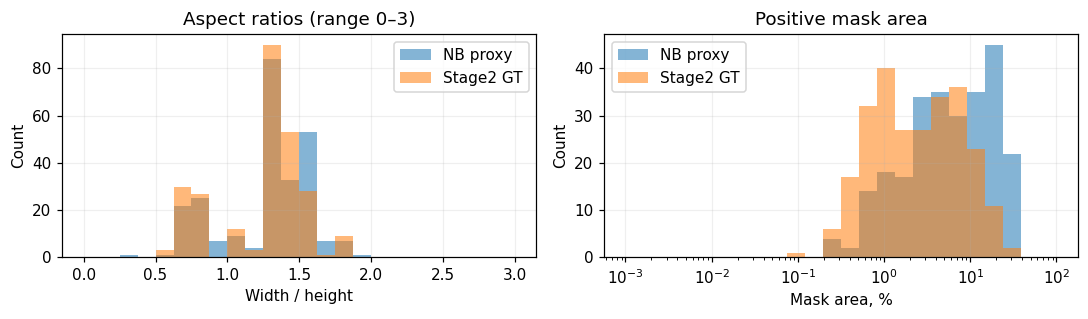

In [2]:
def geometry(frame, label):
    rows = []
    selected = frame[frame.gt_path.ne("")].sample(n=min(SAMPLE, int(frame.gt_path.ne("").sum())), random_state=SEED)
    for row in selected.itertuples():
        image = cv2.imread(str(DATA / row.chng_img_path))
        mask = cv2.imread(str(DATA / row.gt_path), cv2.IMREAD_GRAYSCALE)
        if image is None or mask is None:
            raise FileNotFoundError(row.chng_img_path if image is None else row.gt_path)
        if image.shape[:2] != mask.shape:
            raise ValueError(f"Несовпадение размеров: {row.gt_path}")
        area = float((mask > 127).mean())
        if area > 0:
            h, w = mask.shape
            rows.append(dict(dataset=label, width=w, height=h, aspect=w / h, area=100 * area))
    return pd.DataFrame(rows)

stats = pd.concat([geometry(train, "Stage2 GT"), geometry(val, "NB proxy")], ignore_index=True)
display(stats.groupby("dataset").agg(n=("area", "size"), median_width=("width", "median"),
    median_height=("height", "median"), median_area_pct=("area", "median"),
    masks_below_1pct=("area", lambda x: float((x < 1).mean()))).round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for label, group in stats.groupby("dataset"):
    axes[0].hist(group.aspect, bins=np.linspace(0, 3, 25), alpha=.55, label=label)
    axes[1].hist(group.area, bins=np.geomspace(.001, 100, 25), alpha=.55, label=label)
axes[0].set(xlabel="Width / height", ylabel="Count", title="Aspect ratios (range 0–3)")
axes[1].set(xscale="log", xlabel="Mask area, %", ylabel="Count", title="Positive mask area")
for ax in axes:
    ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

**Наблюдение по этим выборкам:** медианная площадь маски — **2.41% для stage2** и **5.95% для NB**; доля масок меньше1% кадра — **28.1% и9.8%**. Это мотивирует отдельно отслеживать мелкие изменения и не считать NB заменой stage2. NB-панель отобрана по типам правок, поэтому различия не описывают автоматически весь NB train. Типичный исходный кадр в выборках около1024×768: при squish640 меняются и масштаб деталей, и пропорции.

## 2. Примеры масок

По одному фиксированному случайному примеру stage2 и NB. Слева исходник, в центре правка, справа правка с маской. Красная область — официальная GT для stage2 и приблизительная разностная маска для NB. Эти два примера иллюстрируют формат, а не оценивают среднее качество разметки.

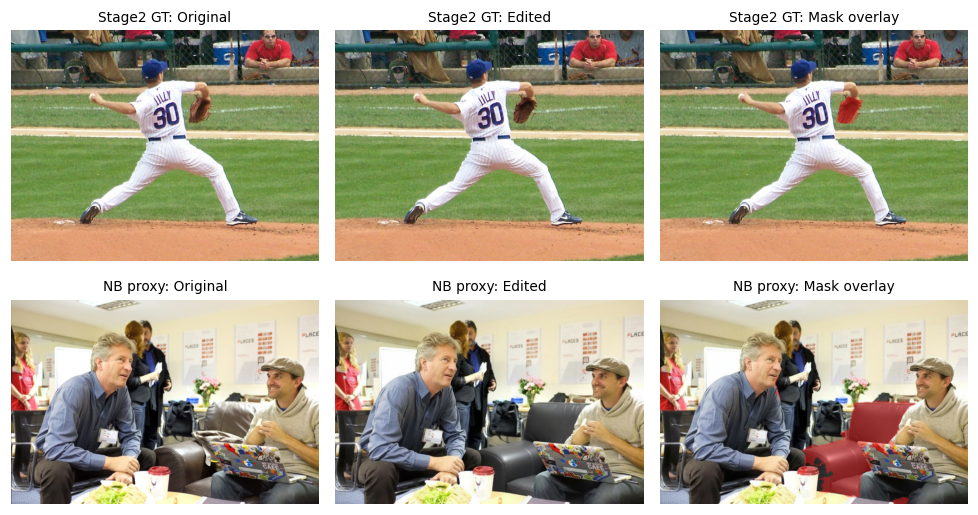

In [3]:
examples = [
    ("Stage2 GT", train[train.gt_path.ne("")].sample(1, random_state=SEED).iloc[0]),
    ("NB proxy", val.sample(1, random_state=SEED).iloc[0]),
]
fig, axes = plt.subplots(2, 3, figsize=(9, 5))
for i, (label, row) in enumerate(examples):
    original = cv2.cvtColor(cv2.imread(str(DATA / row.orgl_img_path)), cv2.COLOR_BGR2RGB)
    edited = cv2.cvtColor(cv2.imread(str(DATA / row.chng_img_path)), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(str(DATA / row.gt_path), cv2.IMREAD_GRAYSCALE) > 127
    overlay = edited.copy()
    overlay[mask] = (.55 * overlay[mask] + .45 * np.array([255, 30, 30])).astype(np.uint8)
    for ax, image, title in zip(axes[i], [original, edited, overlay], ["Original", "Edited", "Mask overlay"]):
        ax.imshow(image)
        ax.set_title(f"{label}: {title}", fontsize=9)
        ax.axis("off")
fig.tight_layout()
display(fig)
plt.close(fig)

## 3. Ключевые сравнения

Зафиксированные результаты находятся в `report_experiments.csv`: public LB конкретных посылок и единый пересчёт NB550. **NB Dice/FPR/AIC везде при пороге0.75**; колонка `threshold` относится к посылке на платформе. FPR — доля чистых кадров с предсказанной площадью ≥1%. AIC — гармоническое среднее Dice и (1−FPR).

NB550 — 550 правок и 550 чистых исходников; из NB600 исключены50 пар с выявленными пересечениями ранних обучающих списков. Проверка путей не заменяет аудит содержимого и предобучения. NB-оценки приблизительные и неоднократно использовались при разработке. Public LB также не является независимым итоговым private-результатом. Исторические решения по эпохам/порогам с использованием тестовых диагностических панелей не становятся независимой валидацией от этого пересчёта.

Сравнения ретроспективные: местами меняются одновременно данные, эпоха и порог. Без повторов по seed они не дают изолированного причинного эффекта каждой модификации.

,submission,change,threshold,nb_dice,nb_fpr,nb_aic,public_lb
0,53,Без NB; late-average + SWA,0.93,0.2496,24.91%,0.3746,0.76411
1,64,NB без чистых исходников,0.93,0.4225,40.00%,0.4958,0.75717
2,71,NB + парные исходники,0.93,0.4249,8.00%,0.5813,0.78488
3,76,"Чистые маски v2, 2000 пар / 24 эпохи",0.93,0.5277,5.45%,0.6773,0.79538
4,85,Отбор по согласию с моделью №78,0.93,0.5405,4.91%,0.6892,0.80229
5,88,Без синтетических правок и зума,0.93,0.5515,3.45%,0.7020,0.80204
6,93,"Упрощённый рецепт, 40 эпох",0.93,0.5529,2.91%,0.7046,0.80232
7,109,"CFL: cross-fit учителя, hard-цели",0.93,0.5687,5.45%,0.7102,0.80957
8,112,"Тот же CFL e21, порог 0.80",0.80,0.5687,5.45%,0.7102,0.81608
9,113,"KDALL: мягкие цели, пул 9693 NB",0.75,0.5813,2.55%,0.7282,0.82279


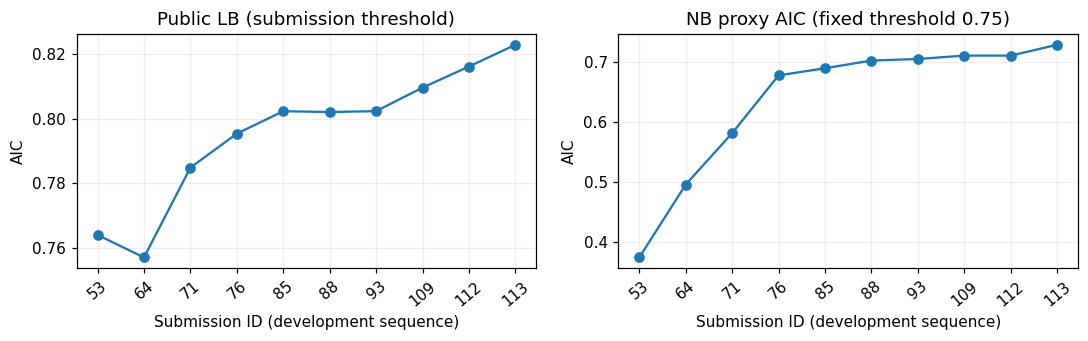

In [4]:
results = pd.read_csv(REPO / "stage2/report_experiments.csv")
table = results.copy()
for column, pattern in {"threshold": "{:.2f}", "nb_dice": "{:.4f}", "nb_fpr": "{:.2%}", "nb_aic": "{:.4f}", "public_lb": "{:.5f}"}.items():
    table[column] = table[column].map(pattern.format)
display(table)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
x = np.arange(len(results))
for ax, column, title in zip(axes, ["public_lb", "nb_aic"], ["Public LB (submission threshold)", "NB proxy AIC (fixed threshold 0.75)"]):
    ax.plot(x, results[column], "o-", linewidth=1.5)
    ax.set_xticks(x, results.submission.astype(str), rotation=40)
    ax.set(xlabel="Submission ID (development sequence)", ylabel="AIC", title=title)
fig.tight_layout()
display(fig)
plt.close(fig)

## 4. Что следует из экспериментов

- **Парные чистые исходники нужны вместе с NB-правками.** №64→№71: public LB0.75717→0.78488; NB FPR40%→8%. У чекпойнтов различаются эпохи, поэтому это не полностью изолированная абляция.
- **Разработка целей дала следующий шаг.** Более чистые маски и отбор пар по согласию с моделью довели результат до №85:0.80229. Изменялись и состав, и длительность обучения — не весь эффект относится к одному алгоритму масок.
- **Больше аугментаций не всегда лучше.** Удаление синтетических правок и positive zoom (№85→№88) оставило LB практически тем же:0.80229→0.80204. Более простой рецепт стал основой дальнейших опытов.
- **Разделяем обучение и порог.** №109 и№112 — те же веса CFL e21:0.80957→0.81608 получено сменой порога. Их NB-метрики в таблице одинаковы.
- **Итоговый подход — мягкие NB-цели и широкий пул при постоянной дозе.** KDALL №113:0.82279. Каждую NB-пару размечал один cross-fit ConvNeXt-L, не обученный на её NB-фолде; официальная stage2 GT и чистые исходники сохраняют hard-цели. В финальном инференсе одна MiT-B2. По сравнению с CFL менялись также охват пула, эпоха и порог, поэтому изолированный выигрыш soft labels пока не измерен.

**Ограничения:** разностные NB-маски шумные; небольшие различия не проверены повторами по seed; совпадение архитектуры не означает совпадение постановки; NB- и public-ранжирование моделей может различаться. Следующие контролируемые проверки: одинаковая выборка для hard/soft-целей, сохранение дозы при расширении пула, повторы финалистов на нескольких seed.

Полный рецепт, правила подсчёта NB и команда повторного инференса: [README](README.md). Для повторения отчёта нужны `matplotlib`, `ipykernel` и зависимости основного репозитория. Настройте `AIJ_DATA_ROOT` и `AIJ_MANIFESTS`, если данные расположены вне `data/` и `manifests/`.